# Lab 6 tasks

Name: Khair ul wara Hussain

Student Id: FA23-BAI-022

Course: NLP

---
# Lab 06: Text Classification: Naive Bayes & Logistic Regression

## Setup: imports and dataset

In [1]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

In [2]:
# app_reviews.csv -> columns: text, label ('positive' / 'negative').
# If the file is already next to this notebook it is used as it is, otherwise a sample
# (imbalanced) app review dataset is written so that the notebook runs from start to end.
if not os.path.exists("app_reviews.csv"):
    random.seed(7)
    features = ["camera feature", "dashboard", "sync", "login screen", "notifications", "search",
                "payment page", "dark mode", "settings menu", "chat", "upload", "backup"]
    pos_core = ["great app", "i love this app", "works perfectly", "very easy to use",
                "clean and simple design", "highly recommend it", "super fast and smooth",
                "best app i have used", "does exactly what i need", "really helpful and reliable",
                "the new update is awesome", "five stars", "excellent features", "so convenient",
                "never had a problem", "saves me so much time", "beautiful interface",
                "works like a charm", "amazing support team", "totally worth it"]
    neg_core = ["keeps crashing", "completely useless", "total waste of time", "too many ads",
                "i can not log in anymore", "very slow and laggy", "drains my battery",
                "full of bugs", "worst update ever", "cannot sync my data", "support never replied",
                "constantly freezes", "i want a refund", "terrible experience", "keeps logging me out",
                "crashes on startup", "lost all my data", "not worth the money", "unusable now",
                "support is not replying to my emails"]
    pos_feat = ["is great", "works well", "is really smooth", "is much better now", "is so easy"]
    neg_feat = ["is broken", "does not work", "crashes", "is very slow", "is confusing and buggy"]
    neutral = ["it is ok", "i use it every day", "installed it last week", "on my android phone",
               "after the latest update", "for my work", "on my iphone", "since yesterday",
               "i have used it for a month", "the update came today", "", "", ""]
    pos_hard = ["it used to crash but now it works great", "not bad at all, quite useful",
                "a few ads but the app is great", "slow at first but now it is fast and smooth",
                "i expected bugs but it is smooth and reliable", "the old version was useless, this one is great",
                "no crashes so far, very happy", "the update fixed the sync problem",
                "support replied quickly and solved it", "login problem is gone, thank you"]
    neg_hard = ["great idea but it keeps crashing", "i wanted to love this app but it is full of bugs",
                "looks nice but i can not log in", "good design, terrible performance",
                "was great before the update, now it is useless", "love the features but it freezes all the time",
                "nice concept but i want a refund", "not good at all, very slow",
                "the interface is clean but the sync is broken", "used to be my favourite, now it crashes",
                "fast support but the bug is still there", "decent app, too many ads though",
                "not as good as before", "it is ok but it keeps logging me out"]

    def make(core, feat, hard, hard_share):
        r = random.random()
        if r < hard_share:
            parts = [random.choice(hard)]
        elif r < hard_share + 0.3:
            parts = ["the " + random.choice(features) + " " + random.choice(feat)]
        else:
            parts = random.sample(core, random.choice([1, 2]))
        ctx = random.choice(neutral)
        return (", ".join(parts) + " " + ctx).strip()

    rows = [(make(pos_core, pos_feat, pos_hard, 0.20), "positive") for _ in range(660)]
    rows += [(make(neg_core, neg_feat, neg_hard, 0.45), "negative") for _ in range(140)]
    # a few mislabelled rows, like in real review data
    for i in random.sample(range(len(rows)), 24):
        rows[i] = (rows[i][0], "negative" if rows[i][1] == "positive" else "positive")
    random.shuffle(rows)
    pd.DataFrame(rows, columns=["text", "label"]).to_csv("app_reviews.csv", index=False)

In [3]:
df = pd.read_csv("app_reviews.csv")
print("Shape:", df.shape)
df.head()

Shape: (800, 2)


,text,label
0,"really helpful and reliable, amazing support t...",positive
1,"the old version was useless, this one is great...",positive
2,beautiful interface,positive
3,"total waste of time, support never replied",negative
4,"not bad at all, quite useful for my work",positive


## Task 01: Full Pipeline (TF-IDF + Logistic Regression) and Test Metrics

In [4]:
# (a) split the raw text, the pipeline does the vectorization itself
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
print("Train size:", len(X_train_text), "| Test size:", len(X_test_text))

Train size: 640 | Test size: 160


In [5]:
# (b) TF-IDF + Logistic Regression in a single pipeline
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression()),
])
pipeline.fit(X_train_text, y_train)
y_pred = pipeline.predict(X_test_text)

In [6]:
# (c) metrics on the held-out test split ('positive' is the target class here)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label="positive")
rec = recall_score(y_test, y_pred, pos_label="positive")
f1 = f1_score(y_test, y_pred, pos_label="positive")

print("--- TF-IDF + Logistic Regression (positive class) ---")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

--- TF-IDF + Logistic Regression (positive class) ---
Accuracy:  0.9125
Precision: 0.9085
Recall:    0.9923
F1-Score:  0.9485


## Task 02: Confusion Matrix

[[ 17  13]
 [  1 129]]


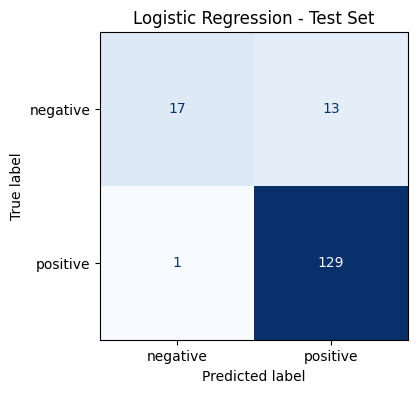

In [7]:
# (a) plot the confusion matrix (rows = true label, columns = predicted label)
labels = ["negative", "positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Logistic Regression - Test Set")
plt.show()

In [8]:
# (b) what the matrix shows
neg_correct, neg_missed, pos_missed, pos_correct = cm.ravel()   # rows: true label, columns: predicted
neg_total, pos_total = neg_correct + neg_missed, pos_missed + pos_correct
neg_recall = neg_correct / neg_total
pos_recall = pos_correct / pos_total

weaker = "negative" if neg_recall < pos_recall else "positive"
print(f"The test set has {neg_total} negative and {pos_total} positive reviews. The model classified "
      f"{pos_correct} of {pos_total} positive reviews correctly (recall {pos_recall:.2f}) and {neg_correct} "
      f"of {neg_total} negative reviews correctly (recall {neg_recall:.2f}).")
print(f"It struggles most with the {weaker} class: {neg_missed} negative reviews were labelled positive "
      f"and {pos_missed} positive review(s) were labelled negative.")
print(f"The overall accuracy of {accuracy_score(y_test, y_pred):.2f} looks strong because the positive class is much "
      f"bigger, but it hides how many of the {neg_total} negative reviews were missed.")

The test set has 30 negative and 130 positive reviews. The model classified 129 of 130 positive reviews correctly (recall 0.99) and 17 of 30 negative reviews correctly (recall 0.57).
It struggles most with the negative class: 13 negative reviews were labelled positive and 1 positive review(s) were labelled negative.
The overall accuracy of 0.91 looks strong because the positive class is much bigger, but it hides how many of the 30 negative reviews were missed.


## Task 03: Most Confident Misclassifications

In [9]:
# (a) DataFrame of every misclassified test example
proba = pipeline.predict_proba(X_test_text)            # columns follow pipeline.classes_
pred_conf = proba.max(axis=1)                          # probability of the predicted class

results = pd.DataFrame({
    "text": X_test_text.values,
    "true_label": y_test.values,
    "predicted_label": y_pred,
    "predicted_probability": pred_conf,
})
errors = results[results["true_label"] != results["predicted_label"]]
print("Classes order in predict_proba:", list(pipeline.classes_))
print("Misclassified test examples:", len(errors), "out of", len(results))

Classes order in predict_proba: ['negative', 'positive']
Misclassified test examples: 14 out of 160


In [10]:
# (b) the 5 cases where the model was most confident and still wrong
top5 = errors.sort_values("predicted_probability", ascending=False).head(5).reset_index(drop=True)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
print(top5.to_string())

                                                      text true_label predicted_label  predicted_probability
0  beautiful interface, works perfectly i use it every day   negative        positive               0.934819
1            the new update is awesome on my android phone   negative        positive               0.870666
2                   the new update is awesome on my iphone   negative        positive               0.864058
3                                very easy to use it is ok   negative        positive               0.838545
4                       unusable now the update came today   negative        positive               0.728567


## Task 04: Class Distribution and Class Balancing

In [11]:
# (a) class distribution
counts = df["label"].value_counts()
print(counts)
print()
print((df["label"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

label
positive    650
negative    150
Name: count, dtype: int64

label
positive    81.2 %
negative    18.8 %
Name: proportion, dtype: str


In [12]:
# (b) retrain with class_weight='balanced' (same split, same vectorizer, only the loss is reweighted)
pipeline_bal = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(class_weight="balanced")),
])
pipeline_bal.fit(X_train_text, y_train)
y_pred_bal = pipeline_bal.predict(X_test_text)

In [13]:
# (c) side-by-side metrics for the negative class
def negative_class_scores(y_true, y_hat):
    return [precision_score(y_true, y_hat, pos_label="negative", zero_division=0),
            recall_score(y_true, y_hat, pos_label="negative", zero_division=0),
            f1_score(y_true, y_hat, pos_label="negative", zero_division=0)]

comparison = pd.DataFrame({
    "Original (Task 01)": negative_class_scores(y_test, y_pred),
    "Balanced": negative_class_scores(y_test, y_pred_bal),
}, index=["Precision (negative)", "Recall (negative)", "F1 (negative)"]).round(4)
comparison["Change"] = (comparison["Balanced"] - comparison["Original (Task 01)"]).round(4)
print(comparison.to_string())

print()
print("Overall accuracy: original =", round(accuracy_score(y_test, y_pred), 4),
      "| balanced =", round(accuracy_score(y_test, y_pred_bal), 4))

                      Original (Task 01)  Balanced  Change
Precision (negative)              0.9444    0.8667 -0.0777
Recall (negative)                 0.5667    0.8667  0.3000
F1 (negative)                     0.7083    0.8667  0.1584

Overall accuracy: original = 0.9125 | balanced = 0.95


## Task 05: Auto-Flagging Negative Reviews

In [14]:
# (a) new unseen customer feedback snippets
new_feedback = [
    "The app crashes every time I open the camera feature",
    "Really love the new dashboard, very smooth and fast",
    "Great idea but it keeps freezing and I lost my data",
    "I can not log in anymore, support is not replying to my emails",
    "Does exactly what I need, easy to use",
    "Too many ads and the app is very slow now",
    "Not bad at all, the update fixed the sync problem",
    "Worst update ever, I want a refund",
]
new_pred = pipeline.predict(new_feedback)
neg_idx = list(pipeline.classes_).index("negative")
neg_prob = pipeline.predict_proba(new_feedback)[:, neg_idx]

feedback_df = pd.DataFrame({"feedback": new_feedback, "prediction": new_pred,
                            "P(negative)": neg_prob.round(3)})
pd.set_option("display.max_colwidth", 70)
print(feedback_df.to_string())

                                                         feedback prediction  P(negative)
0            The app crashes every time I open the camera feature   positive        0.389
1             Really love the new dashboard, very smooth and fast   positive        0.084
2             Great idea but it keeps freezing and I lost my data   negative        0.535
3  I can not log in anymore, support is not replying to my emails   negative        0.582
4                           Does exactly what I need, easy to use   positive        0.093
5                       Too many ads and the app is very slow now   negative        0.592
6               Not bad at all, the update fixed the sync problem   positive        0.155
7                              Worst update ever, I want a refund   positive        0.425


In [15]:
# (b) the snippets that would be flagged for the support team
flagged = feedback_df[feedback_df["prediction"] == "negative"]
print(f"Flagged as negative: {len(flagged)} of {len(feedback_df)} snippets\n")
for text in flagged["feedback"]:
    print("-", text)

Flagged as negative: 3 of 8 snippets

- Great idea but it keeps freezing and I lost my data
- I can not log in anymore, support is not replying to my emails
- Too many ads and the app is very slow now


In [16]:
# (c) recommendation based on the negative class precision and recall of the Task 01 pipeline
neg_p, neg_r, neg_f = negative_class_scores(y_test, y_pred)
bal_p, bal_r, bal_f = negative_class_scores(y_test, y_pred_bal)
n_neg_test = int((y_test == "negative").sum())
missed = int(round((1 - neg_r) * n_neg_test))

print("Recommendation:")
print(f"On the held-out test set the model reached a precision of {neg_p:.2f} and a recall of {neg_r:.2f} "
      f"for the negative class, so about {neg_p * 100:.0f}% of the reviews it flags really are negative "
      f"but it only catches about {neg_r * 100:.0f}% of all negative reviews ({missed} of {n_neg_test} were missed).")
if neg_r < 0.8:
    print("The flags can be trusted when they appear, but the model cannot be the only filter because "
          "many unhappy customers would never reach the support team.")
else:
    print("The flags are mostly dependable, but a few unhappy customers would still be missed.")
print(f"Using class_weight='balanced' changes the negative recall to {bal_r:.2f} while precision moves to "
      f"{bal_p:.2f}, which suits a support team that prefers a few extra reviews to check over missing unhappy users.")
print("Recommendation: use the balanced model for flagging, keep a periodic manual check of unflagged "
      "reviews, and collect more labelled negative reviews to improve it.")

Recommendation:
On the held-out test set the model reached a precision of 0.94 and a recall of 0.57 for the negative class, so about 94% of the reviews it flags really are negative but it only catches about 57% of all negative reviews (13 of 30 were missed).
The flags can be trusted when they appear, but the model cannot be the only filter because many unhappy customers would never reach the support team.
Using class_weight='balanced' changes the negative recall to 0.87 while precision moves to 0.87, which suits a support team that prefers a few extra reviews to check over missing unhappy users.
Recommendation: use the balanced model for flagging, keep a periodic manual check of unflagged reviews, and collect more labelled negative reviews to improve it.
